# **Lab 9 – Morphological Operations (Solution)**

**Objective:** apply erosion, dilation, opening and closing to different images, and investigate how the
**shape** and **size** of the structuring element (kernel) affect the result.

| Part | Content |
|---|---|
| Part A | Lab demonstrations (erosion, dilation, opening, closing, boundary extraction) |
| Task 1 | All four operations applied to a new binary image (**Balls**) |
| Task 2 | Erosion & dilation with **square, cross, ellipse** kernels of size **3×3, 5×5, 7×7** |

> Image files used (must be in the same folder as this notebook): `Erosion.jpg`, `Open_Closing.jpg`,
> `Opening2.jpg`, `BoundaryExtraction.jpg`, `Balls.png`, `Letters.jpg`.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 90

def show(images, titles, rows, cols, figsize=(12, 6), suptitle=None):
    # Display a list of images in a grid (binary images in gray scale, no axes)
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, 'gray', vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis('off')
    if suptitle:
        plt.suptitle(suptitle, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

def stats(img):
    # white-pixel percentage and number of separate white objects (8-connectivity)
    white = 100 * np.count_nonzero(img) / img.size
    n_obj = cv2.connectedComponents(img, connectivity=8)[0] - 1
    return white, n_obj

---
# **Part A – Lab Demonstrations**
## A.1 Erosion
Erosion shrinks white regions: a pixel stays white only if **every** pixel under the kernel is white,
so thin lines and small details disappear first. Bigger kernels erode more aggressively.

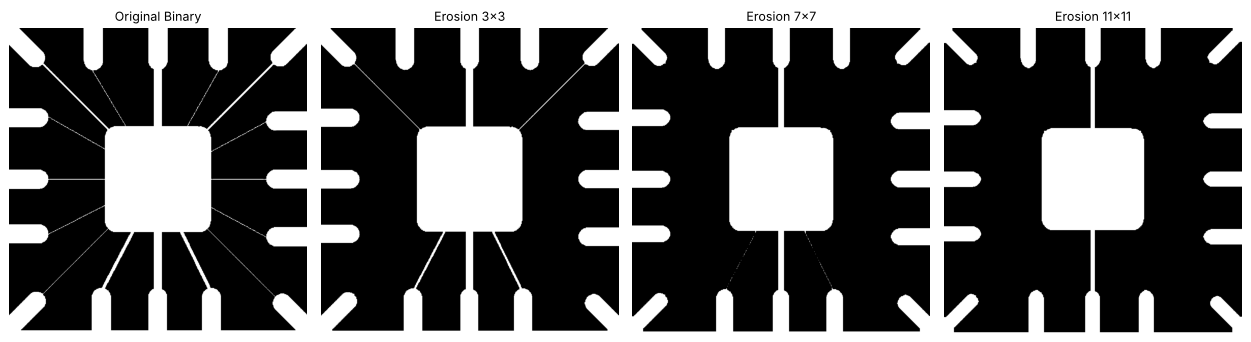

In [2]:
imgFile = 'Erosion.jpg'

img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

show([binary, eroded_img3, eroded_img7, eroded_img11],
     ['Original Binary', 'Erosion 3x3', 'Erosion 7x7', 'Erosion 11x11'], 1, 4, (14, 4))

The thin bonding wires vanish as the kernel grows (3×3 removes the thinnest, 11×11 removes almost all of them),
while the large pad in the centre only gets slightly smaller.

## A.2 Dilation
Dilation grows white regions: a pixel becomes white if **any** pixel under the kernel is white.

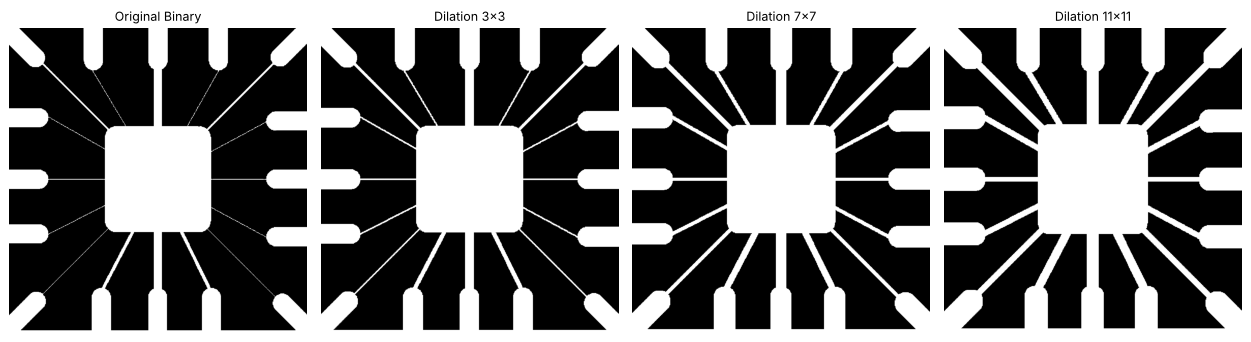

In [3]:
dilated_img3 = cv2.dilate(binary, kernel3, iterations=1)
dilated_img7 = cv2.dilate(binary, kernel7, iterations=1)
dilated_img11 = cv2.dilate(binary, kernel11, iterations=1)

show([binary, dilated_img3, dilated_img7, dilated_img11],
     ['Original Binary', 'Dilation 3x3', 'Dilation 7x7', 'Dilation 11x11'], 1, 4, (14, 4))

The wires and pads become thicker as the kernel size increases.

## A.3 Opening (erosion → dilation)
Removes small white noise while keeping the size/shape of the larger objects.

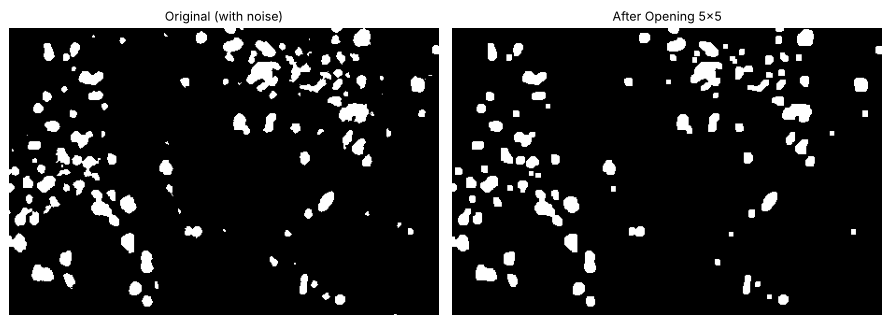

In [4]:
imgFile = 'Open_Closing.jpg'
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)   # = dilate(erode(binary))

show([binary, opening], ['Original (with noise)', 'After Opening 5x5'], 1, 2, (10, 3.6))

## A.4 Closing (dilation → erosion)
Fills small black holes / gaps inside white objects and joins nearby parts.

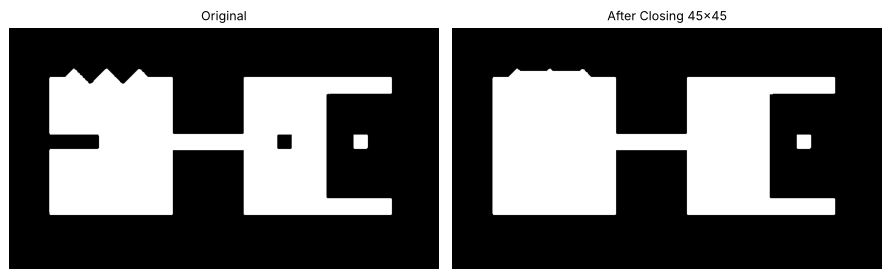

In [5]:
imgFile = 'Opening2.jpg'
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((45, 45), np.uint8)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)  # = erode(dilate(binary))

show([binary, closing], ['Original', 'After Closing 45x45'], 1, 2, (10, 3.2))

The black slot on the left and the small black square are filled; gaps narrower than the kernel are closed.

## A.5 Boundary Extraction

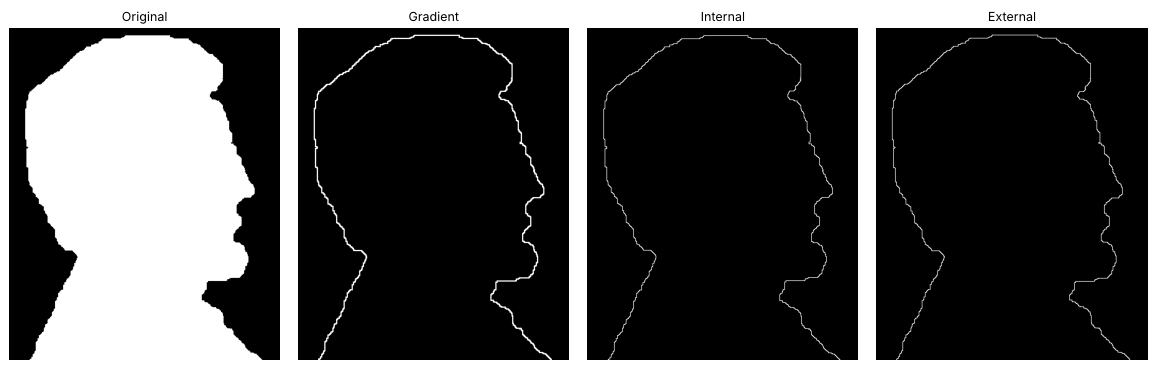

In [6]:
imgFile = 'BoundaryExtraction.jpg'
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((3, 3), np.uint8)
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)   # dilated - eroded
internal = cv2.subtract(binary, cv2.erode(binary, kernel))         # original - eroded
external = cv2.subtract(cv2.dilate(binary, kernel), binary)        # dilated - original

show([binary, gradient, internal, external],
     ['Original', 'Gradient', 'Internal', 'External'], 1, 4, (13, 4))

---
# **Task 1 – Morphological Operations on a New Image (Balls)**

### Step 1: Load and binarize
The balls image is **dark objects on a white background**, so it is inverted (`THRESH_BINARY_INV`) to make the
balls the white foreground. The thin black frame around the photo is cropped (8 px) so it is not treated as an object.

Otsu's automatic threshold (≈167) loses the light-coloured balls (cue ball, ball 1, ball 9), so a fixed threshold of **215** is
used instead; it keeps all 16 balls (the numbers/stripes stay as small holes and specks, which is useful for testing
opening and closing).

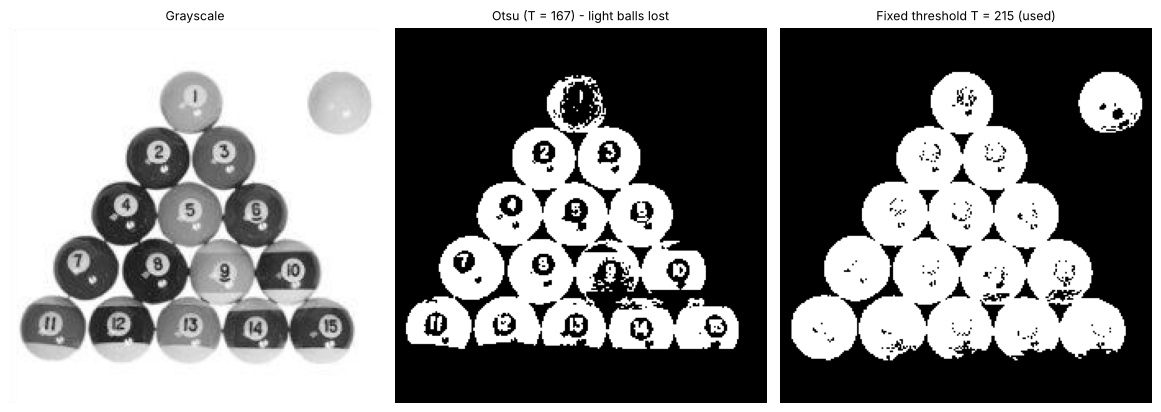

Image size: (229, 227)


In [7]:
imgFile = 'Balls.png'

img = cv2.imread(imgFile, 0)
img = img[8:-8, 8:-8]                       # remove the black frame of the photo

otsu_T, binary_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
_, binary = cv2.threshold(img, 215, 255, cv2.THRESH_BINARY_INV)

show([img, binary_otsu, binary],
     ['Grayscale', f'Otsu (T = {otsu_T:.0f}) - light balls lost', 'Fixed threshold T = 215 (used)'],
     1, 3, (13, 4.5))
print('Image size:', img.shape)

### Step 2: Apply erosion, dilation, opening and closing (5×5 square kernel)

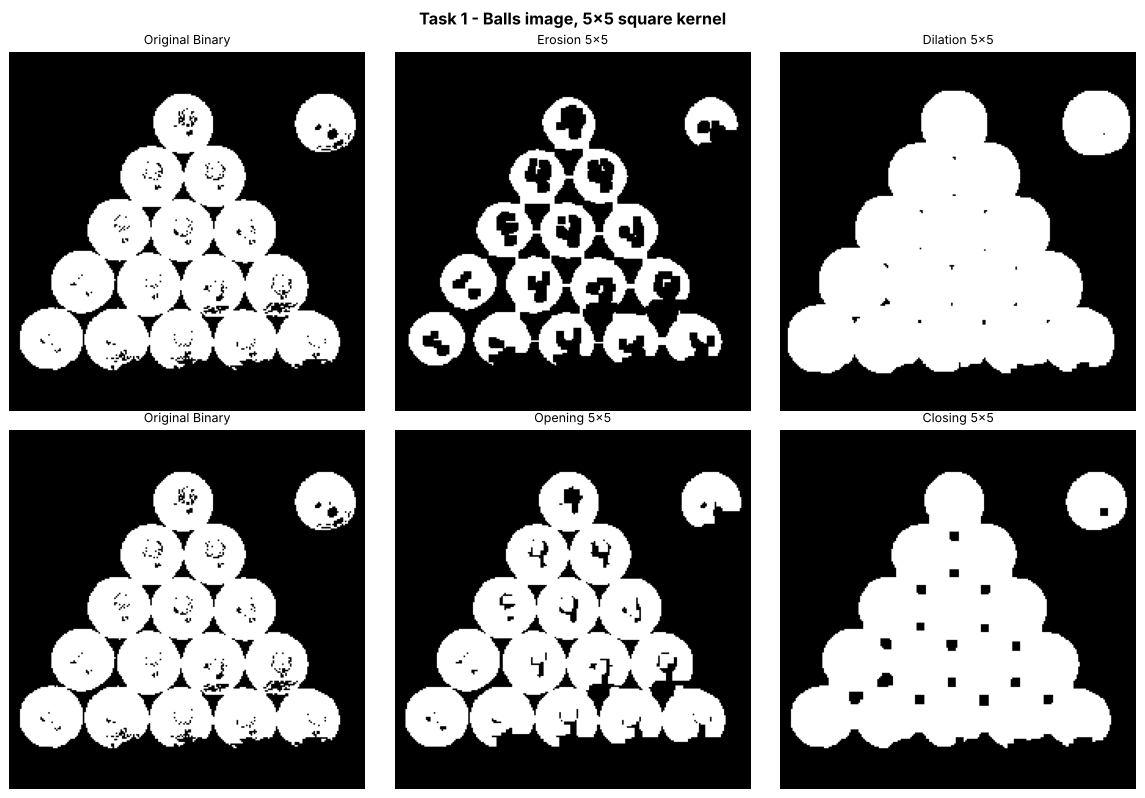

In [8]:
kernel = np.ones((5, 5), np.uint8)

erosion  = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)    # erosion then dilation
closing  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)   # dilation then erosion

show([binary, erosion, dilation, binary, opening, closing],
     ['Original Binary', 'Erosion 5x5', 'Dilation 5x5',
      'Original Binary', 'Opening 5x5', 'Closing 5x5'],
     2, 3, (13, 9), suptitle='Task 1 - Balls image, 5x5 square kernel')

### Step 3: Effect of kernel size (as in the lab: 3×3, 7×7, 11×11)

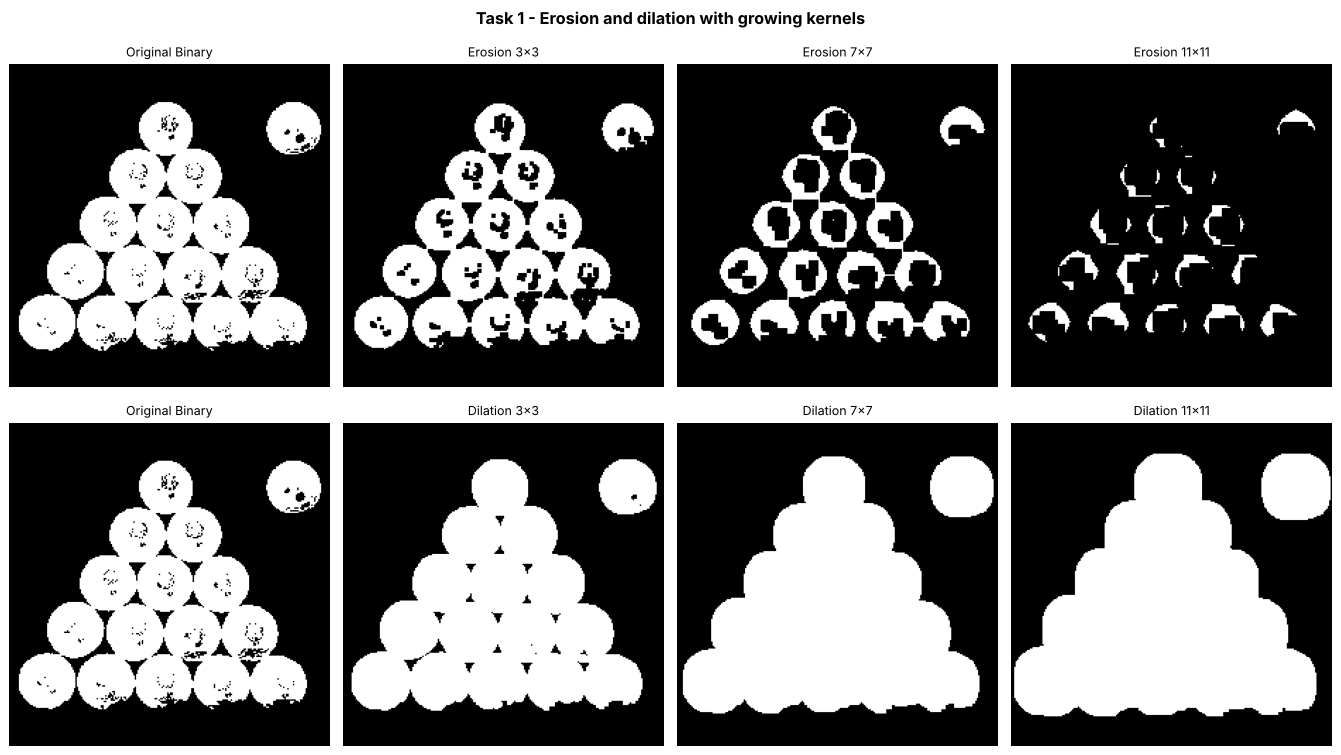

In [9]:
sizes = [3, 7, 11]
ims, tts = [binary], ['Original Binary']
for k in sizes:
    ims.append(cv2.erode(binary, np.ones((k, k), np.uint8))); tts.append(f'Erosion {k}x{k}')
ims.append(binary); tts.append('Original Binary')
for k in sizes:
    ims.append(cv2.dilate(binary, np.ones((k, k), np.uint8))); tts.append(f'Dilation {k}x{k}')

show(ims, tts, 2, 4, (15, 8.8), suptitle='Task 1 - Erosion and dilation with growing kernels')

### Step 4: Numerical comparison
`white %` = percentage of white (foreground) pixels; `objects` = number of separate white regions.

In [10]:
results = {'Original': binary, 'Erosion 5x5': erosion, 'Dilation 5x5': dilation,
           'Opening 5x5': opening, 'Closing 5x5': closing}
for k in [3, 7, 11]:
    results[f'Erosion {k}x{k}'] = cv2.erode(binary, np.ones((k, k), np.uint8))

print(f"{'Result':<16}{'white %':>10}{'objects':>10}")
print('-' * 36)
for name, im in results.items():
    w, n = stats(im)
    print(f'{name:<16}{w:>10.2f}{n:>10}')

Result             white %   objects
------------------------------------
Original             36.37         8
Erosion 5x5          22.03         8
Dilation 5x5         44.34         2
Opening 5x5          34.76         2
Closing 5x5          39.11         2
Erosion 3x3          28.97         8
Erosion 7x7          15.51         9
Erosion 11x11         4.82        36


### Task 1 – Observations

| Operation (5×5 square) | white % | What happened to the balls |
|---|---|---|
| Original binary | 36.4 % | 16 balls; numbers/stripes appear as small black holes; balls touch each other |
| **Erosion** | 22.0 % | Balls shrink and the gaps between them open up, so most balls look separated; the black holes (numbers) **grow**, so each ball becomes a thick ring. With 11×11 the balls break into many small pieces. |
| **Dilation** | 44.3 % | Balls grow and merge into one solid triangle (only 2 objects left: the triangle + the cue ball); small holes from the numbers are filled. |
| **Opening** | 34.8 % | Size of the balls is almost unchanged (only 1.6 % lost), but thin white bits and rough edges are removed, so the outlines become smoother. Holes are not filled. |
| **Closing** | 39.1 % | Small black holes (numbers, specks, noisy stripe areas) are **filled** and the small gaps between neighbouring balls are closed; only gaps bigger than the kernel (the triangular spaces between balls) remain. |

**Key points**
* Erosion and dilation are opposites: erosion removes foreground pixels (36.4 % → 22.0 %), dilation adds them (36.4 % → 44.3 %).
* Opening and closing keep the object size close to the original (34.8 % and 39.1 %) because each one is an erosion
  and a dilation with the same kernel - they only remove details **smaller than the kernel**:
  opening removes small **white** details, closing removes small **black** details.
* Increasing the kernel size (3 → 7 → 11) makes both erosion and dilation stronger (erosion 29.0 % → 15.5 % → 4.8 % white).

---
# **Task 2 – Experimenting with Structuring Elements**

Kernels are created with `cv2.getStructuringElement(shape, (k, k))` for three shapes and three sizes:

| Shape | OpenCV flag |
|---|---|
| Square (rectangle) | `cv2.MORPH_RECT` |
| Cross | `cv2.MORPH_CROSS` |
| Ellipse (disk) | `cv2.MORPH_ELLIPSE` |

In [11]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

kernels = {(s, k): cv2.getStructuringElement(shapes[s], (k, k)) for s in shapes for k in sizes}

# Print the kernels side by side (1 = part of the structuring element)
for k in sizes:
    blocks = [kernels[(s, k)] for s in shapes]
    W = 22                                               # column width
    print(f'----- {k}x{k} -----')
    print(''.join(f'{s} ({K.sum()} ones)'.ljust(W) for s, K in zip(shapes, blocks)))
    for r in range(k):
        print(''.join(' '.join(str(v) for v in K[r]).ljust(W) for K in blocks))
    print()

----- 3x3 -----
Square (9 ones)       Cross (5 ones)        Ellipse (5 ones)      
1 1 1                 0 1 0                 0 1 0                 
1 1 1                 1 1 1                 1 1 1                 
1 1 1                 0 1 0                 0 1 0                 

----- 5x5 -----
Square (25 ones)      Cross (9 ones)        Ellipse (17 ones)     
1 1 1 1 1             0 0 1 0 0             0 0 1 0 0             
1 1 1 1 1             0 0 1 0 0             1 1 1 1 1             
1 1 1 1 1             1 1 1 1 1             1 1 1 1 1             
1 1 1 1 1             0 0 1 0 0             1 1 1 1 1             
1 1 1 1 1             0 0 1 0 0             0 0 1 0 0             

----- 7x7 -----
Square (49 ones)      Cross (13 ones)       Ellipse (33 ones)     
1 1 1 1 1 1 1         0 0 0 1 0 0 0         0 0 0 1 0 0 0         
1 1 1 1 1 1 1         0 0 0 1 0 0 0         0 1 1 1 1 1 0         
1 1 1 1 1 1 1         0 0 0 1 0 0 0         1 1 1 1 1 1 1         
1 1 1 1 1 1 

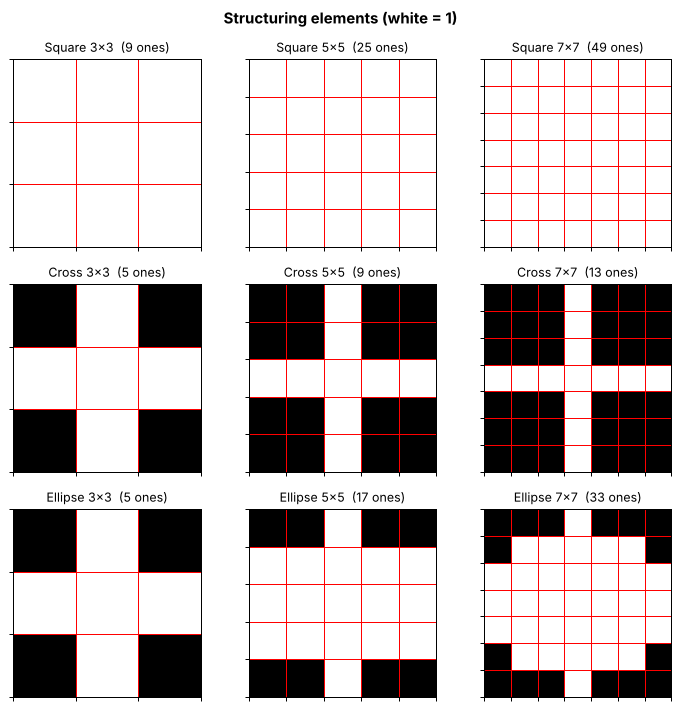

In [12]:
# Visualise the 9 structuring elements
plt.figure(figsize=(8, 8))
i = 1
for s in shapes:
    for k in sizes:
        plt.subplot(3, 3, i); i += 1
        K = kernels[(s, k)]
        plt.imshow(K, 'gray', vmin=0, vmax=1)
        plt.xticks(np.arange(-.5, k), []); plt.yticks(np.arange(-.5, k), [])
        plt.grid(color='red', linewidth=0.8)
        plt.title(f'{s} {k}x{k}  ({K.sum()} ones)', fontsize=10)
plt.suptitle('Structuring elements (white = 1)', fontweight='bold')
plt.tight_layout(); plt.show()

## 2.1 Erosion with different shapes and sizes (Balls image)
Rows = kernel shape, columns = kernel size.

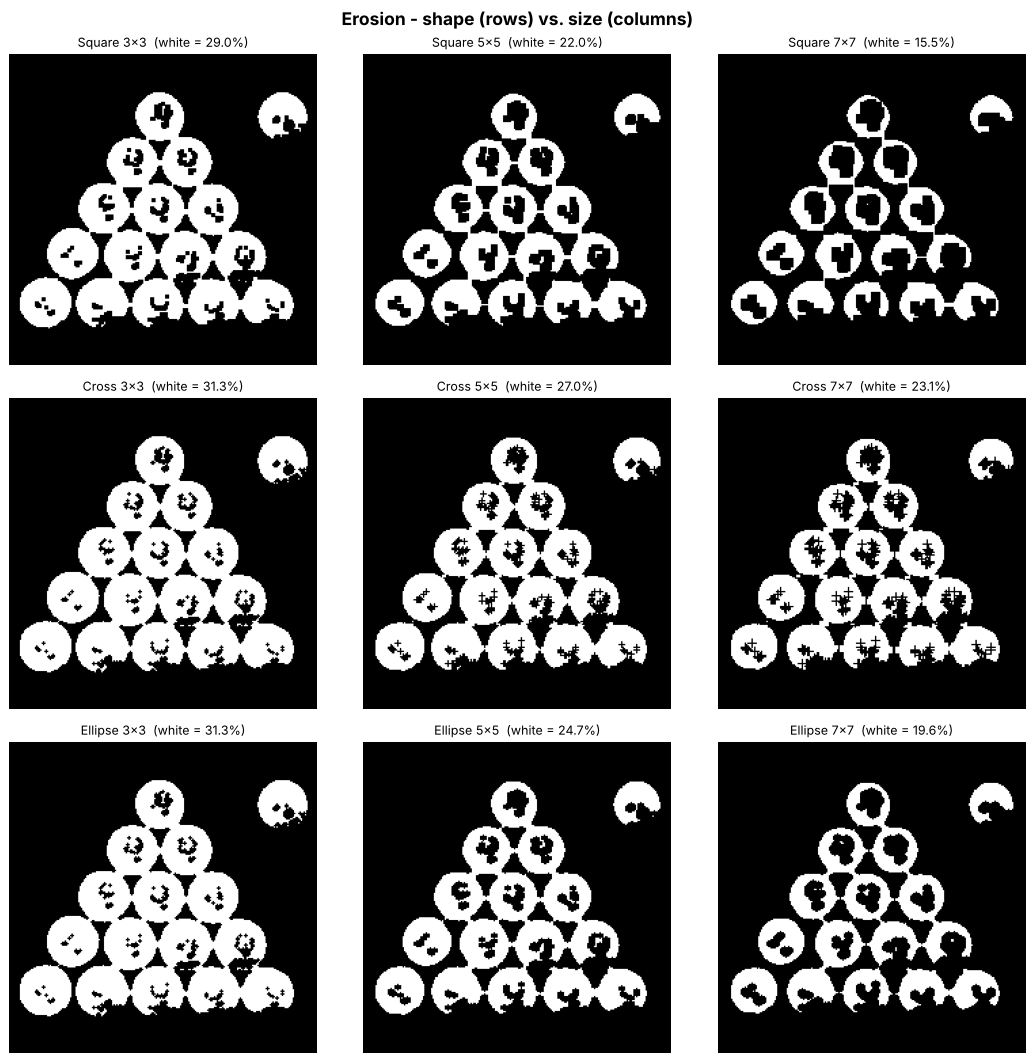

In [13]:
def grid(op, img, title):
    plt.figure(figsize=(12, 12))
    i = 1
    for s in shapes:
        for k in sizes:
            res = op(img, kernels[(s, k)])
            w, _ = stats(res)
            plt.subplot(3, 3, i); i += 1
            plt.imshow(res, 'gray', vmin=0, vmax=255); plt.axis('off')
            plt.title(f'{s} {k}x{k}  (white = {w:.1f}%)', fontsize=10)
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()

grid(cv2.erode, binary, 'Erosion - shape (rows) vs. size (columns)')

## 2.2 Dilation with different shapes and sizes (Balls image)

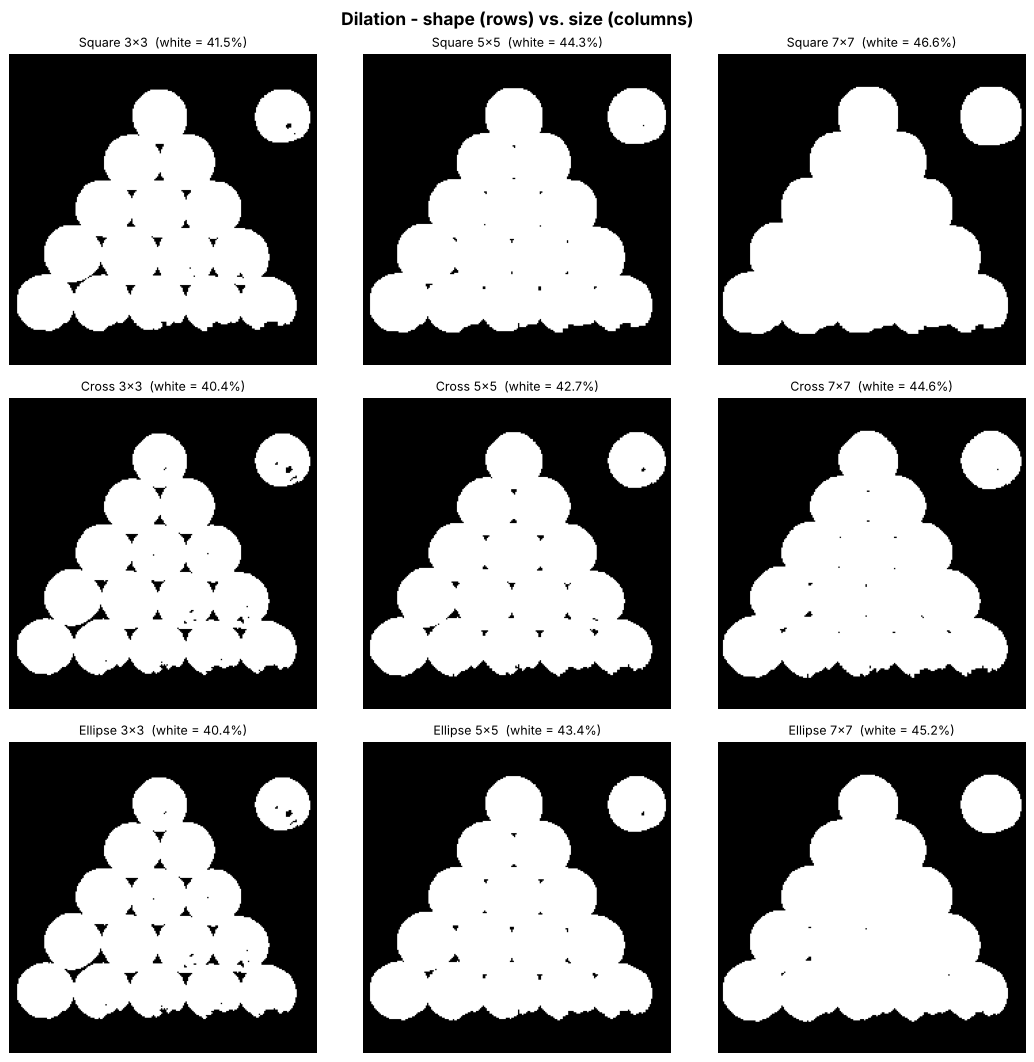

In [14]:
grid(cv2.dilate, binary, 'Dilation - shape (rows) vs. size (columns)')

## 2.3 Numerical comparison table

In [15]:
w0, _ = stats(binary)
print(f'Original binary: white = {w0:.2f}%\n')
print(f"{'Kernel':<14}{'ones':>6} | {'Erosion white %':>16} | {'Dilation white %':>17}")
print('-' * 60)
for k in sizes:
    for s in shapes:
        K = kernels[(s, k)]
        we = stats(cv2.erode(binary, K))[0]
        wd = stats(cv2.dilate(binary, K))[0]
        print(f'{s + " " + str(k) + "x" + str(k):<14}{K.sum():>6} | {we:>16.2f} | {wd:>17.2f}')
    print('-' * 60)

Original binary: white = 36.37%

Kernel          ones |  Erosion white % |  Dilation white %
------------------------------------------------------------
Square 3x3         9 |            28.97 |             41.45
Cross 3x3          5 |            31.27 |             40.38
Ellipse 3x3        5 |            31.27 |             40.38
------------------------------------------------------------
Square 5x5        25 |            22.03 |             44.34
Cross 5x5          9 |            27.04 |             42.73
Ellipse 5x5       17 |            24.66 |             43.40
------------------------------------------------------------
Square 7x7        49 |            15.51 |             46.55
Cross 7x7         13 |            23.09 |             44.56
Ellipse 7x7       33 |            19.57 |             45.19
------------------------------------------------------------


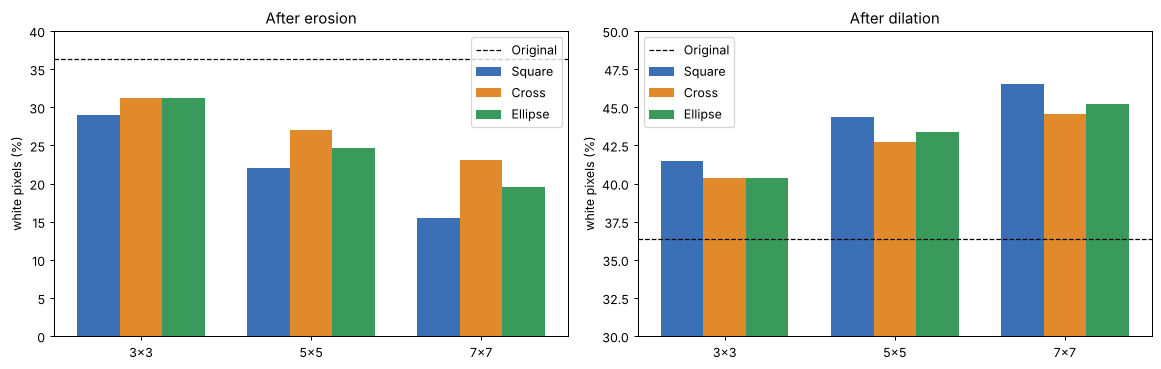

In [16]:
# Same numbers as a chart: how much foreground each kernel removes / adds
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(sizes)); wbar = 0.25
colors = {'Square': '#3b6fb6', 'Cross': '#e08a2c', 'Ellipse': '#3a9a5b'}
for j, s in enumerate(shapes):
    ero = [stats(cv2.erode(binary, kernels[(s, k)]))[0] for k in sizes]
    dil = [stats(cv2.dilate(binary, kernels[(s, k)]))[0] for k in sizes]
    ax[0].bar(x + (j - 1) * wbar, ero, wbar, label=s, color=colors[s])
    ax[1].bar(x + (j - 1) * wbar, dil, wbar, label=s, color=colors[s])
for a, t in zip(ax, ['After erosion', 'After dilation']):
    a.axhline(w0, color='k', ls='--', lw=1, label='Original')
    a.set_xticks(x); a.set_xticklabels([f'{k}x{k}' for k in sizes])
    a.set_ylabel('white pixels (%)'); a.set_title(t); a.legend()
ax[0].set_ylim(0, 40); ax[1].set_ylim(30, 50)
plt.tight_layout(); plt.show()

## 2.4 Clearer view of the kernel *shape* (Letters image)
On round balls the three shapes look similar, so the same 7×7 kernels are applied to a text image, where the sharp
corners of the letters show the shape of the structuring element clearly. The letters are black on white, so the
image is inverted first. `iterations=3` is used only to exaggerate the effect so it is visible.

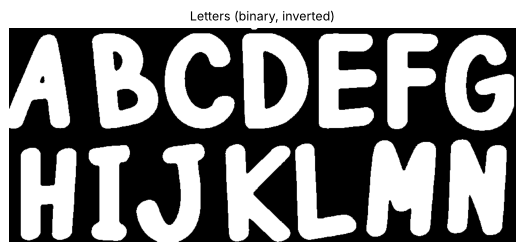

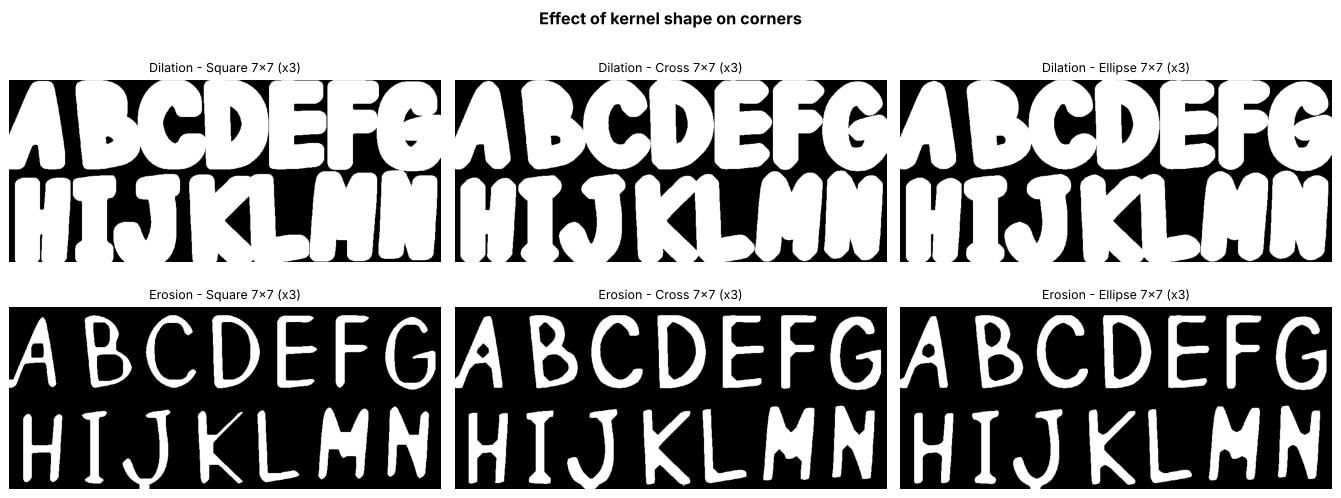

In [17]:
let = cv2.imread('Letters.jpg', 0)
_, let_bin = cv2.threshold(let, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
let_bin = let_bin[:400, :]          # first two rows of letters (A-N) for a bigger view

ims, tts = [], []
for s in shapes:
    ims.append(cv2.dilate(let_bin, kernels[(s, 7)], iterations=3)); tts.append(f'Dilation - {s} 7x7 (x3)')
for s in shapes:
    ims.append(cv2.erode(let_bin, kernels[(s, 7)], iterations=3)); tts.append(f'Erosion - {s} 7x7 (x3)')

show([let_bin], ['Letters (binary, inverted)'], 1, 1, (6, 2.8))
show(ims, tts, 2, 3, (15, 6), suptitle='Effect of kernel shape on corners')

### Task 2 – Comparison and Conclusions

**1. Effect of kernel size** - for every shape, a bigger kernel gives a stronger effect:

| Shape | Erosion 3×3 → 5×5 → 7×7 (white %) | Dilation 3×3 → 5×5 → 7×7 (white %) |
|---|---|---|
| Square | 29.0 → 22.0 → 15.5 | 41.5 → 44.3 → 46.6 |
| Cross | 31.3 → 27.0 → 23.1 | 40.4 → 42.7 → 44.6 |
| Ellipse | 31.3 → 24.7 → 19.6 | 40.4 → 43.4 → 45.2 |

**2. Effect of kernel shape** - at the same size the strength follows the number of 1s in the kernel:
**Square (9 / 25 / 49) > Ellipse (5 / 17 / 33) > Cross (5 / 9 / 13)**.
For example, 7×7 erosion leaves 15.5 % white with the square, 19.6 % with the ellipse and 23.1 % with the cross.

**3. 3×3 ellipse = 3×3 cross** - in OpenCV the 3×3 elliptical kernel is exactly the same matrix as the 3×3 cross
(5 ones), so their results are identical (31.3 % / 40.4 %). The difference between the two only appears from 5×5 upward.

**4. Visual differences**
* **Square:** strongest effect; edges and enlarged holes become blocky with square corners.
* **Cross:** weakest effect; holes grow into "+" shapes and outlines become jagged / diamond-like, because the kernel
  only acts horizontally and vertically (no diagonal neighbours).
* **Ellipse:** in between; produces round, smooth outlines, so the balls keep their circular shape best.
* On the letters (2.4) the kernel shape is copied onto the corners: square → square corners, cross → bevelled
  (diamond) corners, ellipse → rounded corners.

**Conclusion:** the **size** of the structuring element controls *how much* the image changes, and its **shape**
controls *how* the edges change. For round objects like the balls the **elliptical kernel** is the best choice,
because it shrinks/grows the objects evenly in all directions without adding square or cross-shaped artefacts.

---
# **Summary**

| Operation | What it does | Typical use |
|---|---|---|
| Erosion | Shrinks white objects, removes thin parts, separates touching objects | Remove small noise, split objects |
| Dilation | Grows white objects, fills small holes, joins nearby objects | Fill gaps, connect broken parts |
| Opening (erode → dilate) | Removes white specks smaller than the kernel, keeps object size | Salt-noise removal |
| Closing (dilate → erode) | Fills black holes/gaps smaller than the kernel, keeps object size | Fill holes inside objects |

* **Size:** a bigger kernel = a stronger effect (the change grows roughly with the kernel radius).
* **Shape:** the strength follows the number of ones in the kernel — **Square > Ellipse > Cross** — and the kernel's
  shape is copied onto the object edges (square → sharp square corners, cross → diagonal/diamond corners,
  ellipse → rounded corners). An elliptical kernel is the natural choice for round objects like the balls.